# La ecuación clásica del tamaño medio en un tiro, con la corrección de resistencia de Cunningham

**Nivel 1: Fundamentos** · Requiere: 01-the-data/02-geometry-reconstruction · Tiempo de lectura: unos 20 minutos

## Objetivos

El peldaño más antiguo de la escalera es una ecuación cerrada: el tamaño medio de Kuznetsov de 1973 con la corrección de resistencia del explosivo que agregó Cunningham. No necesita datos de entrenamiento, solo una geometría en metros y un número para la roca. Este cuaderno la ejecuta en un solo tiro y luego en una campaña completa.

Al terminar habrá:

- escrito la ecuación término a término y comprobado que coincide con `kuznetsov_x50_m` del motor en el tiro `En1` de Enusa;
- visto la predicción de los 12 tiros de Enusa frente a las mediciones y leído el número del artefacto versionado para el mismo tiro;
- entendido qué representa el factor de roca `A`, que el cuaderno siguiente abre.

## Preparación

Instale los paquetes con los pines exactos de `notebooks/requirements.txt`. El motor es `blastfrag`, publicado en PyPI; los otros paquetes son su base numérica y la biblioteca de gráficos.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

Esta celda aún no importa nada del cuaderno: lee las versiones instaladas desde los metadatos de los paquetes y las imprime, de modo que la salida registra qué motor produjo cada número que sigue.

In [1]:
# Imprima la versión instalada de cada paquete que usa este cuaderno
from importlib.metadata import version

for name in ("blastfrag", "numpy", "matplotlib",):
    print(f"{name}=={version(name)}")

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Datos

| Fuente | Titular y URL | Clase de licencia | Archivo que lee el cuaderno |
|---|---|---|---|
| Los 12 tiros de Enusa, con `x50` medido | Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 | hechos numéricos reutilizados con cita; el artículo nunca se distribuye | el corpus dentro del paquete `blastfrag` |
| La ecuación tal como se imprime | Amoako, Jha y Zhong 2022, https://doi.org/10.3390/mining2020013 (Ecs. 2 y 3) | la ecuación se reproduce con cita | `kuznetsov_x50_m` del motor |
| El caso Enusa versionado | este repositorio (MIT), escrito por la ejecución offline | la licencia propia del producto | `data/derived/real-enusa/case.json` |

## Método

El tamaño medio de fragmento en centímetros es

```
x50 = A * (V / Q)^0.8 * Q^(1/6) * (RWS / 115)^(-19/30)
```

con `V` el volumen de roca arrancado por pozo (m3), `Q` la masa de explosivo en él (kg), `RWS` la resistencia relativa en peso del explosivo en la escala donde el ANFO vale 100, y `A` el factor de roca. El 115 es la resistencia del TNT en esa escala, y el exponente -19/30 es la corrección de Cunningham tal como la imprimen Hudaverdi, Kulatilake y Kuzu 2010 (https://doi.org/10.1002/nag.957, Ec. 1) y Amoako, Jha y Zhong 2022 (https://doi.org/10.3390/mining2020013, Ecs. 2 y 3). Circulan dos escrituras del exponente (-19/30 y -19/20); el motor usa -19/30 como lo imprimen los dos artículos y conserva -19/20 como variante con nombre. Todos los tiros de este corpus usaron ANFO, así que la elección solo reescala el factor de roca recuperado desde las predicciones publicadas; el SDD registra que la preferencia no se ha contrastado con el texto de Cunningham.

Lectura de los términos: `(V/Q)^0.8` es el recíproco del factor de carga, de modo que una carga más rica da una fragmentación más fina; `Q^(1/6)` permite que un pozo mayor fragmente algo más grueso al mismo factor de carga; el término de resistencia hace más fino a un explosivo más fuerte.

### Paso 1: el tiro y su patrón

La celda carga el corpus, elige `En1` y reconstruye su patrón absoluto (el cuaderno 02 del tema anterior). El factor de roca de Enusa se lee de la tabla de factores por sitio del motor, `SITE_ROCK_FACTOR`; de dónde sale ese número es el tema del cuaderno siguiente.

In [2]:
# Importaciones, el corpus, un tiro y su patrón reconstruido
import json
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

DERIVED = Path("../../../data/derived")
train = bf.load_training_corpus()
blast = next(b for b in train if b.blast_id == "En1")
pattern = bf.reconstruct_pattern(blast)
rock_factor = bf.SITE_ROCK_FACTOR[blast.site]
print("tiro", blast.blast_id, "|", blast.site, "| factor de roca A =", rock_factor)
print(f"V = {pattern.rock_volume_m3:.3f} m3 | Q = {pattern.charge_mass_kg:.3f} kg | RWS = {pattern.explosive.rws:g} ({pattern.explosive.name})")

tiro En1 | Enusa | factor de roca A = 10.97
V = 150.238 m3 | Q = 72.114 kg | RWS = 100 (ANFO)


### Paso 2: la ecuación, un término por línea

Cada factor de la ecuación recibe su propia variable, de modo que cada intermedio es visible. La última línea compara el producto con `kuznetsov_x50_m` del motor.

In [3]:
# Los cuatro factores de la ecuación, y luego su producto en centímetros y metros
V = pattern.rock_volume_m3
Q = pattern.charge_mass_kg
volume_term = (V / Q) ** 0.8
hole_term = Q ** (1 / 6)
strength_term = (pattern.explosive.rws / 115.0) ** (-19.0 / 30.0)
x50_cm = rock_factor * volume_term * hole_term * strength_term
print(f"(V/Q)^0.8 = {volume_term:.4f}   Q^(1/6) = {hole_term:.4f}   (RWS/115)^(-19/30) = {strength_term:.4f}")
print(f"x50 = {x50_cm:.2f} cm = {x50_cm / 100:.4f} m   (a mano)")
engine = bf.kuznetsov_x50_m(pattern, rock_factor)
print(f"x50 = {engine:.4f} m   (motor)   igual: {abs(engine - x50_cm / 100) < 1e-12}")

(V/Q)^0.8 = 1.7989   Q^(1/6) = 2.0402   (RWS/115)^(-19/30) = 1.0926
x50 = 43.99 cm = 0.4399 m   (a mano)
x50 = 0.4399 m   (motor)   igual: True


### Paso 3: comparar con la medición y con el artefacto versionado

La ejecución offline escribió la predicción de este tiro en `case.json` redondeada a seis decimales. La celda la lee de vuelta, pide al brazo `Kuznetsov` (que también reconstruye el patrón y busca el factor) el mismo tiro, y pone el tamaño medido junto a ambos.

In [4]:
# El brazo, el artefacto versionado y la medición para el mismo tiro
artifact = json.loads((DERIVED / "real-enusa" / "case.json").read_text(encoding="utf-8"))
arm = bf.Kuznetsov()
prediction = arm.predict_one(blast)
committed = artifact["predictions"]["kuznetsov"][blast.blast_id]["x50_m"]
print("predicción del brazo:", round(prediction.x50_m, 6), "m")
print("artefacto versionado:", committed, "m")
print("medido:", blast.x50_m, "m")
print("lo que la predicción lleva consigo:", sorted(prediction.detail))

predicción del brazo: 0.439872 m
artefacto versionado: 0.439872 m
medido: 0.37 m
lo que la predicción lleva consigo: ['charge_mass_kg', 'rock_factor', 'rock_factor_origin', 'rock_volume_m3', 'timing_factor']


### Paso 4: la campaña completa

Un tiro no prueba nada, así que la celda predice los 12 tiros de Enusa, los puntúa con `bf.score` (que nombra cada estadístico) y dibuja lo predicho contra lo medido con la línea de identidad.

tiros puntuados: 12 | abstenciones: 0
RMSE = 0.147 m | sesgo = +0.105 m | MAE = 0.122 m | MAPE = 34.9 %
r2 de Pearson (la correlación al cuadrado) = 0.017
varianza explicada respecto de la línea de identidad = -1.643
igual al puntaje versionado: True


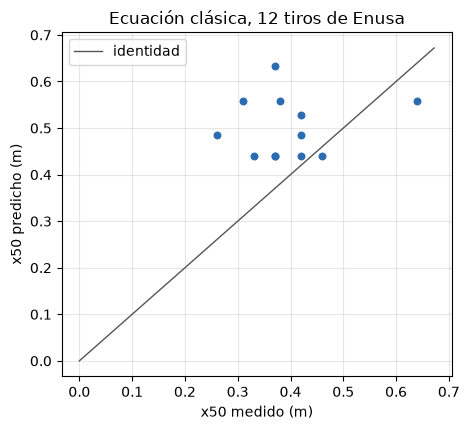

In [5]:
# Predecir los 12 tiros de Enusa y puntuarlos contra las mediciones
enusa = [b for b in train if b.site == "Enusa"]
predictions = arm.predict(enusa)
score = bf.score(enusa, predictions, method="kuznetsov")
print("tiros puntuados:", score.n_scored, "| abstenciones:", score.n_abstained)
print(f"RMSE = {score.rmse_m:.3f} m | sesgo = {score.bias_m:+.3f} m | MAE = {score.mae_m:.3f} m | MAPE = {score.mape_pct:.1f} %")
print(f"r2 de Pearson (la correlación al cuadrado) = {score.pearson_r2:.3f}")
print(f"varianza explicada respecto de la línea de identidad = {score.r2_identity:.3f}")
print("igual al puntaje versionado:", abs(score.r2_identity - artifact["scores"]["kuznetsov"]["r2_identity"]) < 1e-9)

measured = np.array([b.x50_m for b in enusa])
predicted = np.array([p.x50_m for p in predictions])
fig, ax = plt.subplots(figsize=(4.8, 4.4))
ax.scatter(measured, predicted, s=22, color="#2b6cb0")
limit = max(measured.max(), predicted.max()) * 1.05
ax.plot([0, limit], [0, limit], color="#555", lw=1, label="identidad")
ax.set_xlabel("x50 medido (m)")
ax.set_ylabel("x50 predicho (m)")
ax.set_title("Ecuación clásica, 12 tiros de Enusa")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## Resultados

**La ecuación es un producto de cuatro factores visibles.** Escrita término a término reproduce el motor a precisión de máquina, y el artefacto versionado guarda la misma predicción a seis decimales. Nada está oculto dentro del brazo: reconstruye el patrón, busca un factor y aplica la fórmula.

**En Enusa la predicción clásica es alta.** El motor predice fragmentos más gruesos que los medidos en promedio (el sesgo es positivo), y los tamaños predichos varían en una banda más estrecha que los medidos. El gráfico de paridad muestra la nube sobre la línea de identidad.

**Dos estadísticos, dos historias.** El r2 de Pearson y la varianza explicada respecto de la línea de identidad son cantidades distintas con significados distintos, y el producto siempre nombra cuál informa. Aquí difieren mucho porque dentro de una campaña los tamaños medidos varían muy poco, de modo que una predicción 0,1 m alta en promedio explica menos que una constante. Esto no es un defecto de la ecuación en Enusa; es la razón de que un puntaje dentro de un solo sitio diga poco, y de que el producto después agrupe muchos sitios.

**Qué no muestra esto.** El factor de roca de Enusa salió de las predicciones publicadas de esta misma campaña, de modo que la concordancia del nivel es en parte circular. El cuaderno siguiente abre ese número y muestra qué se toma prestado y qué no.

## Resumen

- La ecuación clásica son cuatro factores: un término de volumen, un término de tamaño de pozo, una corrección de resistencia y un factor de roca.
- El motor, un cálculo a mano y el artefacto versionado coinciden en el mismo tiro.
- Dentro de una campaña un puntaje lo domina la poca dispersión de las mediciones; compare puntajes entre sitios, no dentro de uno.
- Siguiente: el cuaderno 02 abre el factor de roca, el único número que la ecuación no puede calcular desde la tabla.

## Referencias

- Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 (Ec. 1, el corpus)
- Amoako, Jha y Zhong 2022, https://doi.org/10.3390/mining2020013 (Ecs. 2 y 3, la ecuación y sus unidades)
- Kuznetsov 1973 y Cunningham 1983, 1987 y 2005 son los originales de la ecuación y sus correcciones; el SDD registra que sus textos primarios no se tuvieron a la vista, así que este cuaderno los cita solo a través de los dos artículos anteriores.
- `blastfrag` 0.4.0, el motor, en PyPI: https://pypi.org/project/blastfrag/